# 💰 QuickLoan — The Great Model Bake-Off
### Ensemble Learning challenge · Notebook submission

**Business question:** which model should QuickLoan deploy to decide *approve or reject* — judged by **money saved**, not just accuracy?

**Roadmap (mirrors the brief):**
1. Load, encode and split the data (no leakage)
2. Feel the pain — weak single models
3. Build the four ensembles: **Voting · Bagging · Boosting · Stacking**
4. The leaderboard — accuracy, recall on defaulters, **money saved**
5. The verdict for QuickLoan's leadership
6. *(Stretch)* Save the model → `loan_model.joblib` → run the dashboard (`streamlit run app.py`)

Two extra sections go beyond the brief to make the verdict trustworthy: a **cross-validation check** (is the champion real or just lucky on one split?) and a **cost-matched decision cut-off** (a free improvement that falls straight out of the payoff table).

## 0 · Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib, time
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter, FuncFormatter

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, FixedThresholdClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (VotingClassifier, BaggingClassifier, RandomForestClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier)
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix
from xgboost import XGBClassifier

SEED = 42            # one seed everywhere -> fully reproducible results
INTEREST = 0.20      # interest earned on a good loan (given in the brief)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

## Step 1 — Load & split

First a health check on `loans.csv`: shape, missing values, duplicates, and above all the **class balance** — defaulters are the minority class, which is why accuracy will turn out to be a misleading scoreboard.

In [2]:
df = pd.read_csv("loans.csv")
print("Shape:", df.shape)
display(df.head())
print("\nMissing values per column:\n", df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget balance (default = 1):")
print(df["default"].value_counts().rename({0: "repaid (0)", 1: "defaulted (1)"}).to_string())
print(f"Default rate: {df['default'].mean():.2%}")
display(df.describe().T.round(2))

Shape: (6000, 11)


,age,annual_income,loan_amount,loan_term_months,employment_years,credit_history_months,num_existing_loans,past_defaults,debt_to_income,home_ownership,default
0,24,133500.0,46300.0,24,4.4,170,0,0,0.35,rent,0
1,55,33400.0,40600.0,24,1.6,100,1,0,1.22,mortgage,0
2,49,152100.0,45800.0,36,14.1,253,1,0,0.30,rent,0
3,40,67400.0,32800.0,36,1.4,294,0,0,0.49,rent,0
4,40,143900.0,68900.0,24,14.5,289,1,1,0.48,rent,0



Missing values per column:
 age                      0
annual_income            0
loan_amount              0
loan_term_months         0
employment_years         0
credit_history_months    0
num_existing_loans       0
past_defaults            0
debt_to_income           0
home_ownership           0
default                  0

Duplicate rows: 0

Target balance (default = 1):
default
repaid (0)       5247
defaulted (1)     753
Default rate: 12.55%


,count,mean,std,min,25%,50%,75%,max
age,6000.0,42.45,12.69,21.00,31.00,42.00,54.00,64.0
annual_income,6000.0,96184.63,36000.79,30400.00,70200.00,90200.00,115600.00,361400.0
loan_amount,6000.0,50536.57,26252.72,6700.00,30900.00,45800.00,64400.00,210700.0
loan_term_months,6000.0,33.65,14.37,12.00,24.00,36.00,48.00,60.0
employment_years,6000.0,5.98,4.27,0.00,2.80,5.00,8.10,35.0
credit_history_months,6000.0,149.28,86.61,0.00,75.00,150.00,224.00,299.0
num_existing_loans,6000.0,1.10,1.04,0.00,0.00,1.00,2.00,6.0
past_defaults,6000.0,0.24,0.50,0.00,0.00,0.00,0.00,4.0
debt_to_income,6000.0,0.60,0.40,0.03,0.32,0.51,0.76,3.0
default,6000.0,0.13,0.33,0.00,0.00,0.00,0.00,1.0


**Encoding & split.** `home_ownership` is the only categorical column → one-hot encoded. The split is stratified (so train and test have the same default rate) and `loan_amount` is split alongside so the **test loan amounts are kept aside** for the money calculation.

**No leakage:** the target is never a feature; train/test rows are disjoint; and the only preprocessing that learns from data (scaling) is placed *inside* pipelines, so it is fit on training rows only.

In [3]:
# Encode the single categorical column (home_ownership) -> one-hot dummies.
# (Same encoding that app.py applies, so the saved model and the dashboard stay consistent.)
X = pd.get_dummies(df.drop(columns="default"), columns=["home_ownership"], dtype=int)
y = df["default"]

# Stratified 75/25 split. We carry loan_amount through the split so the TEST loan amounts
# stay aside for the money calculation.  (test_size=0.25, random_state=1, stratify=y is exactly
# the split hard-coded in app.py, so the dashboard's money card reproduces this notebook.)
X_train, X_test, y_train, y_test, loan_train, loan_test = train_test_split(
    X, y, df["loan_amount"], test_size=0.25, random_state=1, stratify=y)

print("Feature columns:", list(X.columns))
print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print(f"Default rate  train: {y_train.mean():.4f}   test: {y_test.mean():.4f}")
print(f"Defaulters in test set: {y_test.sum()}  |  total loan value in test set: AED {loan_test.sum():,.0f}")

# --- leakage checks ---
assert "default" not in X.columns                                    # target is not a feature
assert set(X_train.index).isdisjoint(X_test.index)                   # no row is in both sets
assert (X_train.index == loan_train.index).all() and (X_test.index == loan_test.index).all()
print("\nLeakage checks passed: target not in features, train/test disjoint, loan amounts aligned.")

Feature columns: ['age', 'annual_income', 'loan_amount', 'loan_term_months', 'employment_years', 'credit_history_months', 'num_existing_loans', 'past_defaults', 'debt_to_income', 'home_ownership_mortgage', 'home_ownership_own', 'home_ownership_rent']
Train: (4500, 12)   Test: (1500, 12)
Default rate  train: 0.1256   test: 0.1253
Defaulters in test set: 188  |  total loan value in test set: AED 75,216,900

Leakage checks passed: target not in features, train/test disjoint, loan amounts aligned.


**The money metric** — copied exactly from the brief (interest = 20 %). Every model below is scored by the same `evaluate()` function on the **same test set**, so the leaderboard is fair.

Two reference strategies first: *approve everyone* (saves AED 0 by definition) and *reject everyone*.

In [4]:
def money_saved(y_true, y_pred, loan_amounts, interest=0.20):
    """EXACT metric from the brief: AED saved vs. approving everyone."""
    y_true = np.array(y_true); y_pred = np.array(y_pred); loan = np.array(loan_amounts)
    caught_defaulter = (y_pred == 1) & (y_true == 1)   # correctly rejected a defaulter -> loan SAVED
    wrongly_rejected = (y_pred == 1) & (y_true == 0)   # rejected a good borrower   -> interest LOST
    return loan[caught_defaulter].sum() - interest * loan[wrongly_rejected].sum()

results = []          # the leaderboard is built up in this list
fitted  = {}          # every fitted model, so we can reuse them later (CV, saving, ...)

def evaluate(name, family, y_pred):
    """Score one model's TEST-set predictions on accuracy, recall (defaulters caught) and money saved."""
    yt, yp, ln = np.array(y_test), np.array(y_pred), np.array(loan_test)
    tp = int(((yp == 1) & (yt == 1)).sum()); fp = int(((yp == 1) & (yt == 0)).sum())
    fn = int(((yp == 0) & (yt == 1)).sum())
    row = dict(Model=name, Family=family,
               Accuracy=accuracy_score(yt, yp), Recall=recall_score(yt, yp, zero_division=0),
               Money_saved=money_saved(yt, yp, ln, INTEREST),
               Defaulters_caught=tp, Good_rejected=fp, Defaulters_missed=fn)
    results.append(row)
    return row

def fit_and_score(name, family, model):
    t0 = time.time()
    model.fit(X_train, y_train)
    fitted[name] = model
    row = evaluate(name, family, model.predict(X_test))      # default 0.5 decision rule
    print(f"{name:<18} acc={row['Accuracy']:.4f}  recall={row['Recall']:.4f}  "
          f"money saved=AED {row['Money_saved']:>12,.0f}   ({time.time()-t0:.1f}s)")

# Reference strategies: approve everyone saves 0 by definition; reject everyone throws good customers away.
evaluate("Approve everyone", "Baseline", np.zeros(len(y_test), dtype=int))
evaluate("Reject everyone",  "Baseline", np.ones(len(y_test),  dtype=int))
display(pd.DataFrame(results).set_index("Model")[["Accuracy", "Recall", "Money_saved"]]
        .style.format({"Accuracy": "{:.2%}", "Recall": "{:.2%}", "Money_saved": "AED {:,.0f}"}))

,Accuracy,Recall,Money_saved
Model,,,
Approve everyone,87.47%,0.00%,AED 0
Reject everyone,12.53%,100.00%,"AED -317,100"


## Step 2 — Feel the pain: weak single models

Three different kinds of single learner: a **shallow Decision Tree**, **Logistic Regression** and **KNN**.

In [5]:
# Three different kinds of weak single learners. LR and KNN are distance/scale-sensitive, so their
# StandardScaler lives INSIDE a pipeline -> it is fit on training data only (no leakage).
dt  = DecisionTreeClassifier(max_depth=4, random_state=SEED)                                   # shallow tree
lr  = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))    # linear model
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))                    # instance-based

for name, mdl in [("Decision Tree", dt), ("Logistic Regression", lr), ("KNN", knn)]:
    fit_and_score(name, "Single", mdl)

Decision Tree      acc=0.8940  recall=0.2660  money saved=AED    3,782,120   (0.0s)
Logistic Regression acc=0.8880  recall=0.2181  money saved=AED    3,307,300   (0.0s)


KNN                acc=0.8813  recall=0.1223  money saved=AED    1,972,840   (0.1s)


In [6]:
singles = pd.DataFrame([r for r in results if r["Family"] == "Single"]).set_index("Model")
display(singles[["Accuracy", "Recall", "Money_saved", "Defaulters_caught", "Defaulters_missed", "Good_rejected"]]
        .style.format({"Accuracy": "{:.2%}", "Recall": "{:.2%}", "Money_saved": "AED {:,.0f}"}))

,Accuracy,Recall,Money_saved,Defaulters_caught,Defaulters_missed,Good_rejected
Model,,,,,,
Decision Tree,89.40%,26.60%,"AED 3,782,120",50,138,21
Logistic Regression,88.80%,21.81%,"AED 3,307,300",41,147,21
KNN,88.13%,12.23%,"AED 1,972,840",23,165,13


**What to notice.** On accuracy all three singles look respectable (88.1 – 89.4 %) — but *approving everyone* already scores 87.47 %. The real weakness is **recall**: the best single model, the Decision Tree, catches only 50 of the 188 defaulters (26.6 %); Logistic Regression catches 41 (21.8 %) and KNN just 23 (12.2 %). Every missed defaulter is a whole loan gone, so money saved ranges only from **AED 1.97 M (KNN) to AED 3.78 M (Decision Tree)**. This is the pain the ensembles are meant to relieve.

## Step 3 — Build the four ensembles

*One expert can be wrong — a committee wins.* Each ensemble below is a different way to run the committee.  
Hyper-parameters are sensible fixed values — **nothing was tuned on the test set**.

### 3.1 Voting — ask *different* experts, average their votes
Combines the three single models from Step 2 (tree + logistic + KNN). **Soft voting** averages their predicted probabilities, which keeps more information than a simple majority of hard votes.

In [7]:
voting = VotingClassifier(
    estimators=[("tree", clone(dt)), ("logit", clone(lr)), ("knn", clone(knn))],
    voting="soft")                      # average the predicted probabilities of 3 *different* model types
fit_and_score("Voting", "Voting", voting)

Voting             acc=0.8900  recall=0.2128  money saved=AED    3,376,260   (0.1s)


### 3.2 Bagging — many copies of the *same* model on different random slices
Bagging fights **variance**: a fully grown tree is unstable, but averaging 200 of them trained on bootstrap samples is not. A Random Forest adds random feature subsets at every split to de-correlate the trees.

In [8]:
# Bagging: 200 full-depth (high-variance) trees, each trained on a bootstrap sample, predictions averaged
bagging = BaggingClassifier(DecisionTreeClassifier(random_state=SEED), n_estimators=200,
                            random_state=SEED, n_jobs=-1)
fit_and_score("Bagging (Trees)", "Bagging", bagging)

# Random Forest: bagging + random feature subsets at every split (de-correlates the trees)
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
fit_and_score("Random Forest", "Bagging", rf)

Bagging (Trees)    acc=0.8907  recall=0.3138  money saved=AED    4,466,960   (3.3s)


Random Forest      acc=0.8933  recall=0.2979  money saved=AED    4,368,200   (1.5s)


### 3.3 Boosting — models in *sequence*, each fixing the previous one's mistakes
Boosting fights **bias**: AdaBoost re-weights the examples that were misclassified; Gradient Boosting and XGBoost fit each new tree to the remaining errors (gradients) of the ensemble so far.

In [9]:
ada = AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEED)               # re-weights mistakes
gb  = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=SEED)
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                    colsample_bytree=0.8, eval_metric="logloss", random_state=SEED, n_jobs=1)

fit_and_score("AdaBoost", "Boosting", ada)
fit_and_score("Gradient Boosting", "Boosting", gb)
fit_and_score("XGBoost", "Boosting", xgb)

AdaBoost           acc=0.8887  recall=0.1862  money saved=AED    2,814,220   (0.6s)


Gradient Boosting  acc=0.8960  recall=0.3351  money saved=AED    4,768,240   (1.1s)
XGBoost            acc=0.8933  recall=0.3138  money saved=AED    4,580,800   (0.1s)


### 3.4 Stacking — a "manager" learns how much to trust each expert
Three strong, different base ensembles feed a simple logistic-regression meta-model.

In [10]:
# Base learners = three strong, different ensembles.  Meta-learner = a simple logistic regression that
# learns how much to trust each one.  cv=5 means the meta-model is trained on OUT-OF-FOLD base predictions
# (so it never sees a base model's predictions on data that base model was trained on -> no leakage).
stacking = StackingClassifier(
    estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb))],
    final_estimator=LogisticRegression(max_iter=1000),
    stack_method="predict_proba", cv=5, n_jobs=1)
fit_and_score("Stacking", "Stacking", stacking)

# What did the manager learn? (meta-model weights on each base model's P(default))
w = stacking.final_estimator_.coef_.ravel()
print("\nMeta-model weights ->", {k: round(float(v), 2) for k, v in zip(["Random Forest", "Gradient Boosting", "XGBoost"], w)})

Stacking           acc=0.8933  recall=0.3138  money saved=AED    4,499,140   (15.9s)

Meta-model weights -> {'Random Forest': 2.38, 'Gradient Boosting': 2.53, 'XGBoost': 1.13}


## Step 4 — The Leaderboard 🏆

**Every** model, one table, same test set: **Accuracy · Recall (defaulters caught) · Money saved.**

In [11]:
lb = (pd.DataFrame(results)
        .sort_values("Money_saved", ascending=False).reset_index(drop=True))
models_only = lb[lb.Family != "Baseline"].copy()
models_only["Rank (accuracy)"] = models_only["Accuracy"].rank(ascending=False, method="min").astype(int)
models_only["Rank (money)"]    = models_only["Money_saved"].rank(ascending=False, method="min").astype(int)
leaderboard = models_only.sort_values("Money_saved", ascending=False).reset_index(drop=True)
leaderboard.index = leaderboard.index + 1

show = leaderboard[["Model", "Family", "Accuracy", "Recall", "Money_saved",
                    "Defaulters_caught", "Good_rejected", "Rank (accuracy)", "Rank (money)"]]
display(show.style.format({"Accuracy": "{:.2%}", "Recall": "{:.2%}", "Money_saved": "AED {:,.0f}"})
            .highlight_max(subset=["Accuracy", "Recall", "Money_saved"], color="#c8f7c5"))

base = lb[lb.Family == "Baseline"].set_index("Model")
print("Reference ->  Approve everyone: accuracy {:.2%}, recall {:.0%}, money saved AED 0   |   "
      "Reject everyone: accuracy {:.2%}, money saved AED {:,.0f}".format(
      base.loc["Approve everyone", "Accuracy"], base.loc["Approve everyone", "Recall"],
      base.loc["Reject everyone", "Accuracy"], base.loc["Reject everyone", "Money_saved"]))

champion_name = leaderboard.iloc[0]["Model"]
print(f"\nCHAMPION on money saved: {champion_name}")

,Model,Family,Accuracy,Recall,Money_saved,Defaulters_caught,Good_rejected,Rank (accuracy),Rank (money)
1,Gradient Boosting,Boosting,89.60%,33.51%,"AED 4,768,240",63,31,1,1
2,XGBoost,Boosting,89.33%,31.38%,"AED 4,580,800",59,31,3,2
3,Stacking,Stacking,89.33%,31.38%,"AED 4,499,140",59,31,3,3
4,Bagging (Trees),Bagging,89.07%,31.38%,"AED 4,466,960",59,35,6,4
5,Random Forest,Bagging,89.33%,29.79%,"AED 4,368,200",56,28,3,5
6,Decision Tree,Single,89.40%,26.60%,"AED 3,782,120",50,21,2,6
7,Voting,Voting,89.00%,21.28%,"AED 3,376,260",40,17,7,7
8,Logistic Regression,Single,88.80%,21.81%,"AED 3,307,300",41,21,9,8
9,AdaBoost,Boosting,88.87%,18.62%,"AED 2,814,220",35,14,8,9
10,KNN,Single,88.13%,12.23%,"AED 1,972,840",23,13,10,10


Reference ->  Approve everyone: accuracy 87.47%, recall 0%, money saved AED 0   |   Reject everyone: accuracy 12.53%, money saved AED -317,100

CHAMPION on money saved: Gradient Boosting


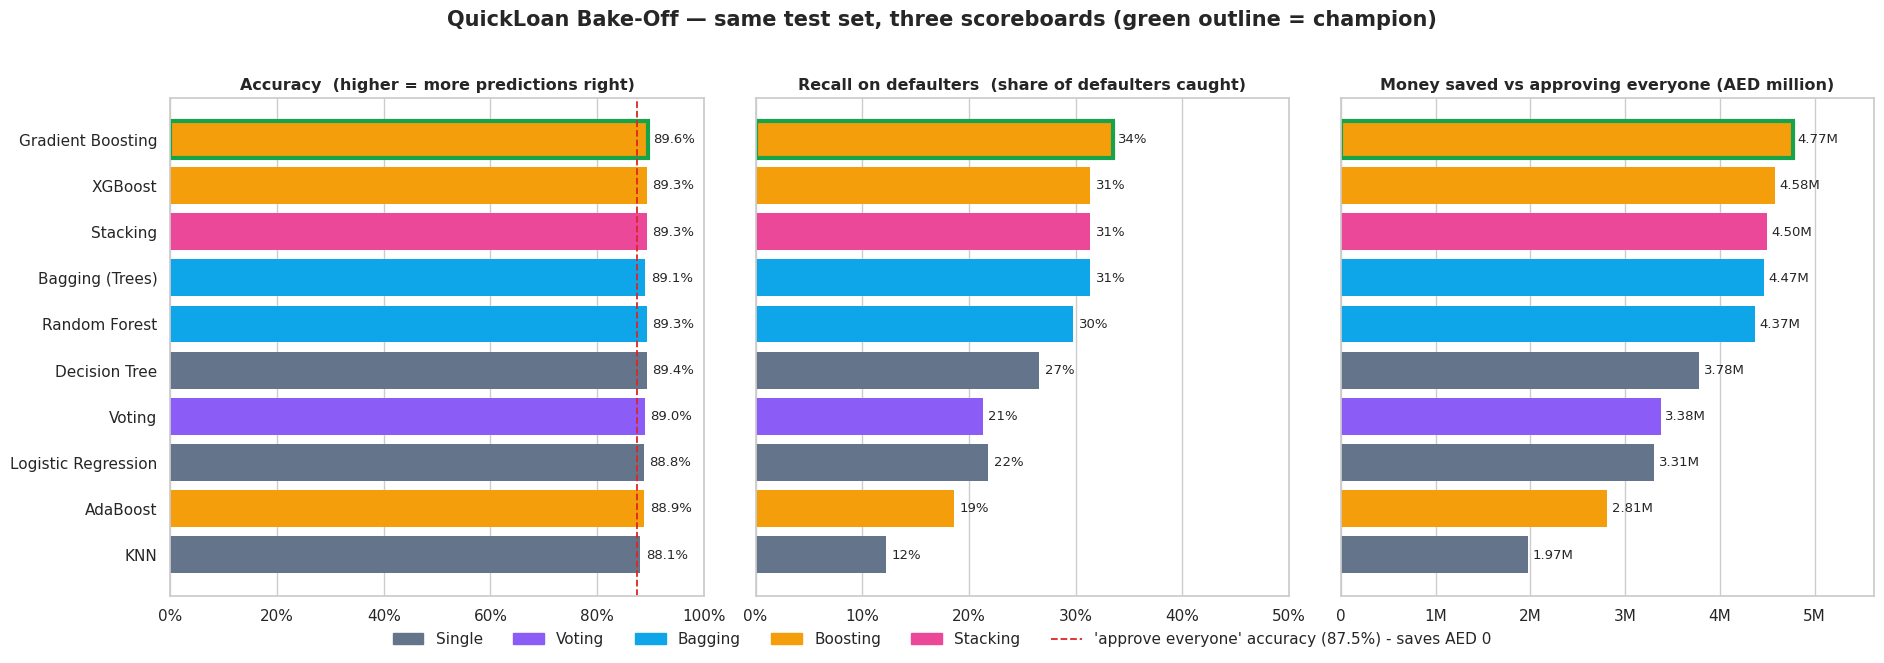

In [12]:
FAM_COL = {"Single": "#64748b", "Voting": "#8b5cf6", "Bagging": "#0ea5e9", "Boosting": "#f59e0b", "Stacking": "#ec4899"}

def leaderboard_figure(lb_df, accuracy_ref, title, path=None, champion=None):
    d = lb_df.sort_values("Money_saved", ascending=True)            # barh: best ends up at the top
    cols = [FAM_COL[f] for f in d.Family]
    fig, axes = plt.subplots(1, 3, figsize=(19, 6.2), sharey=True)
    specs = [("Accuracy", "Accuracy  (higher = more predictions right)", lambda v: f"{v:.1%}", (0, 1)),
             ("Recall", "Recall on defaulters  (share of defaulters caught)", lambda v: f"{v:.0%}", (0, max(0.5, d.Recall.max() * 1.25))),
             ("Money_saved", "Money saved vs approving everyone (AED million)", lambda v: f"{v/1e6:.2f}M", None)]
    for ax, (col, ttl, f, xlim) in zip(axes, specs):
        vals = d[col].values
        ax.barh(d.Model, vals, color=cols, edgecolor=["#16a34a" if m == champion else "none" for m in d.Model],
                linewidth=[3 if m == champion else 0 for m in d.Model])
        for y_i, v in enumerate(vals):
            ax.text(v + (xlim[1] * 0.01 if xlim else max(vals) * 0.01), y_i, f(v), va="center", fontsize=9.5)
        ax.set_title(ttl, fontsize=11.5, fontweight="bold")
        if xlim: ax.set_xlim(*xlim)
        else:    ax.set_xlim(min(0, vals.min()), max(vals) * 1.18)
        ax.grid(axis="y", visible=False)
    axes[0].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axes[1].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axes[2].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1e6:.0f}M" if v else "0"))
    axes[0].axvline(accuracy_ref, color="#dc2626", ls="--", lw=1.3)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAM_COL.values()] + [plt.Line2D([0], [0], color="#dc2626", ls="--", lw=1.3)]
    labels  = list(FAM_COL.keys()) + [f"'approve everyone' accuracy ({accuracy_ref:.1%}) - saves AED 0"]
    fig.legend(handles, labels, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.03))
    fig.suptitle(title, fontsize=15, fontweight="bold", y=1.02)
    plt.tight_layout()
    if path: fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()

leaderboard_figure(leaderboard, base.loc["Approve everyone", "Accuracy"],
                   "QuickLoan Bake-Off — same test set, three scoreboards (green outline = champion)",
                   path="leaderboard_chart.png", champion=champion_name)
leaderboard.to_csv("leaderboard.csv", index_label="Position")

In [13]:
acc_range   = leaderboard.Accuracy.max() - leaderboard.Accuracy.min()
money_range = leaderboard.Money_saved.max() - leaderboard.Money_saved.min()
print(f"Accuracy   : best {leaderboard.Accuracy.max():.2%}  worst {leaderboard.Accuracy.min():.2%}  -> spread {acc_range*100:.2f} percentage points "
      f"({leaderboard.Accuracy.max()/leaderboard.Accuracy.min()-1:+.1%} relative)")
print(f"Recall     : best {leaderboard.Recall.max():.2%}  worst {leaderboard.Recall.min():.2%}  -> best is {leaderboard.Recall.max()/leaderboard.Recall.min():.1f}x the worst")
print(f"Money saved: best AED {leaderboard.Money_saved.max():,.0f}  worst AED {leaderboard.Money_saved.min():,.0f}  -> spread AED {money_range:,.0f} "
      f"(best is {leaderboard.Money_saved.max()/leaderboard.Money_saved.min():.1f}x the worst)")
print(f"\nApprove-everyone already scores {base.loc['Approve everyone','Accuracy']:.2%} accuracy while saving AED 0 -> "
      f"accuracy alone cannot even tell a useful model from a useless one.")
print("Correlation between a model's accuracy and its money saved: "
      f"{leaderboard.Accuracy.corr(leaderboard.Money_saved):.2f}   |   recall vs money saved: {leaderboard.Recall.corr(leaderboard.Money_saved):.2f}")

ens = leaderboard[leaderboard.Family != "Single"]; sgl = leaderboard[leaderboard.Family == "Single"]
print(f"\nBest single model : {sgl.iloc[0].Model} -> AED {sgl.iloc[0].Money_saved:,.0f}")
print(f"Best ensemble     : {ens.iloc[0].Model} -> AED {ens.iloc[0].Money_saved:,.0f}   "
      f"(+AED {ens.iloc[0].Money_saved - sgl.iloc[0].Money_saved:,.0f} vs best single)")

Accuracy   : best 89.60%  worst 88.13%  -> spread 1.47 percentage points (+1.7% relative)
Recall     : best 33.51%  worst 12.23%  -> best is 2.7x the worst
Money saved: best AED 4,768,240  worst AED 1,972,840  -> spread AED 2,795,400 (best is 2.4x the worst)

Approve-everyone already scores 87.47% accuracy while saving AED 0 -> accuracy alone cannot even tell a useful model from a useless one.
Correlation between a model's accuracy and its money saved: 0.90   |   recall vs money saved: 1.00

Best single model : Decision Tree -> AED 3,782,120
Best ensemble     : Gradient Boosting -> AED 4,768,240   (+AED 986,120 vs best single)


### How to read the leaderboard

- **Champion: Gradient Boosting** — AED 4,768,240 saved, 33.5 % recall, 89.6 % accuracy. The top five places are all ensembles; the best single model (Decision Tree, AED 3.78 M) is AED 986,120 behind.
- **Accuracy hides the story.** Accuracy spans just **1.47 points** (88.1 – 89.6 %) while money saved varies **2.4×** (AED 1.97 M – 4.77 M) and recall **2.7×**. Three models tie at 89.33 % accuracy yet save AED 4.58 M, 4.50 M and 4.37 M. The Decision Tree ranks **2nd on accuracy but 6th on money**. Accuracy and money do move in the same general direction here (r = 0.90), but accuracy squeezes a 2.4× business gap into 1.5 points and cannot tell a useful model from "approve everyone" (87.47 %, saves AED 0). Recall tracks money almost perfectly (r = 1.00).
- **Not every ensemble wins.** Voting (AED 3.38 M) and AdaBoost (AED 2.81 M) fall *below* the single Decision Tree. Voting averages in two weak, low-recall members (Logistic Regression, KNN), which drags the committee toward the cautious majority; AdaBoost with its default decision stumps stays a high-bias learner that rarely flags the minority class at a 0.5 cut-off.
- **Bagging vs boosting.** Bagging (Trees 4.47 M, Random Forest 4.37 M) stabilises an unstable learner and beats the single tree; boosting's best members (Gradient Boosting, XGBoost) do better still.
- **Stacking added nothing here.** At AED 4.50 M it sits below its own best base model (Gradient Boosting, 4.77 M); the meta-model leaned mostly on Gradient Boosting and Random Forest (weights 2.53 and 2.38, XGBoost 1.13). It is also about 14× slower to train (15.9 s vs 1.1 s).
- **Where the champion's money comes from:** it saves AED 5.30 M of loans by catching 63 defaulters and gives up AED 0.53 M of interest on 31 wrongly rejected good customers. But it still lets 125 defaulters through — **AED 6.97 M, 57 % of all defaulted principal**. That untapped prize motivates the cut-off section below.
- **What drives the score:** `debt_to_income` and `past_defaults` together account for about 68 % of Gradient Boosting's feature importance.

Gradient Boosting
  + Loans saved (caught 63 of 188 defaulters) : AED    5,297,800
  - Interest lost (31 good customers rejected)   : AED      529,560
  = NET money saved                                 : AED    4,768,240
  ! Still lost on defaulters we missed (125)      : AED    6,974,100   (= 57% of all defaulted principal)
  Interest rate at which the net saving would fall to zero: 200%  -> the result is not sensitive to the 20% interest assumption


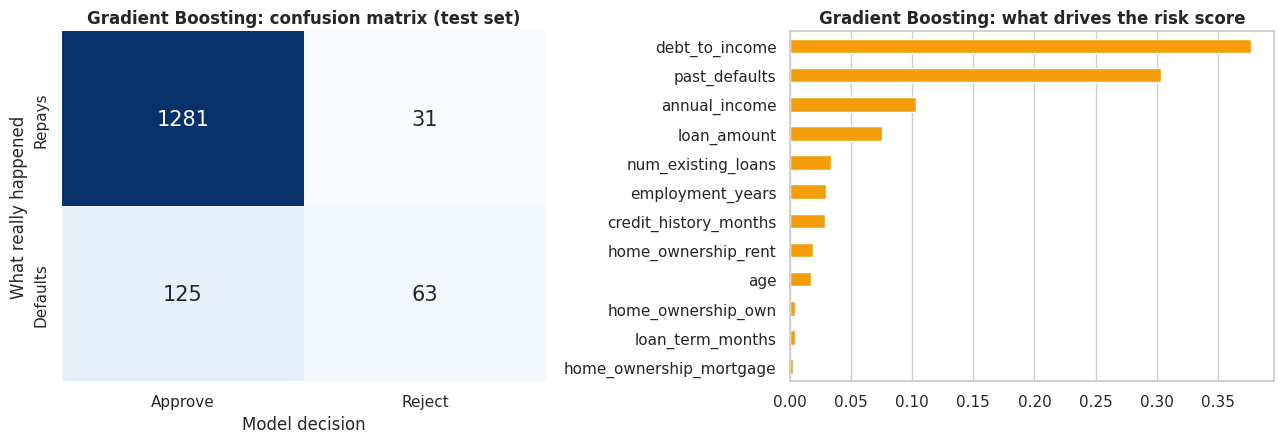

In [14]:
# Where does the champion's money come from?  (the brief's payoff table, made visible)
champ = leaderboard.iloc[0]
champ_pred = fitted[champion_name].predict(X_test)
yt, yp, ln = np.array(y_test), champ_pred, np.array(loan_test)
saved_loans   = ln[(yp == 1) & (yt == 1)].sum()          # defaulters correctly rejected -> loans saved
lost_interest = INTEREST * ln[(yp == 1) & (yt == 0)].sum()   # good borrowers wrongly rejected -> interest lost
missed_loans  = ln[(yp == 0) & (yt == 1)].sum()          # defaulters we still approved -> loans lost
total_def     = ln[yt == 1].sum()
print(f"{champion_name}")
print(f"  + Loans saved (caught {champ.Defaulters_caught} of {int((yt==1).sum())} defaulters) : AED {saved_loans:>12,.0f}")
print(f"  - Interest lost ({champ.Good_rejected} good customers rejected)   : AED {lost_interest:>12,.0f}")
print(f"  = NET money saved                                 : AED {saved_loans - lost_interest:>12,.0f}")
print(f"  ! Still lost on defaulters we missed ({champ.Defaulters_missed})      : AED {missed_loans:>12,.0f}   "
      f"(= {missed_loans/total_def:.0%} of all defaulted principal)")
print(f"  Interest rate at which the net saving would fall to zero: {saved_loans/(lost_interest/INTEREST):.0%}  "
      f"-> the result is not sensitive to the 20% interest assumption")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
cm = confusion_matrix(yt, yp)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Approve", "Reject"], yticklabels=["Repays", "Defaults"], annot_kws={"size": 15})
axes[0].set_title(f"{champion_name}: confusion matrix (test set)", fontweight="bold")
axes[0].set_xlabel("Model decision"); axes[0].set_ylabel("What really happened")
if hasattr(fitted[champion_name], "feature_importances_"):
    imp = pd.Series(fitted[champion_name].feature_importances_, index=X_train.columns).sort_values()
    imp.plot.barh(ax=axes[1], color="#f59e0b"); axes[1].set_title(f"{champion_name}: what drives the risk score", fontweight="bold")
    axes[1].grid(axis="y", visible=False)
else:
    axes[1].axis("off")
plt.tight_layout(); plt.show()

## Is the champion real, or just lucky? — a robustness check

The test set contains only 188 defaulters, so one split can crown the wrong model by luck. I therefore re-score all models with **5-fold stratified cross-validation repeated 3 times (15 folds)**, each model re-trained from scratch on each training fold. The money metric is computed on every held-out fold (~1,200 loans each).

In [15]:
all_models = {r["Model"]: fitted[r["Model"]] for r in results if r["Family"] != "Baseline"}
family_of  = {r["Model"]: r["Family"] for r in results}
THRESH = 1/6          # = 0.20 / 1.20 ; derived in the next section, defined here for reuse
assert abs(THRESH - INTEREST / (1 + INTEREST)) < 1e-12

X_all, y_all = X.reset_index(drop=True), y.reset_index(drop=True)
loan_all = df["loan_amount"].reset_index(drop=True)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

cv = {m: {"0.5": [], "1/6": []} for m in all_models}
t0 = time.time()
for i, (tr, te) in enumerate(rskf.split(X_all, y_all), 1):
    for m, est in all_models.items():
        mdl = clone(est).fit(X_all.iloc[tr], y_all.iloc[tr])
        p = mdl.predict_proba(X_all.iloc[te])[:, 1]
        cv[m]["0.5"].append(money_saved(y_all.iloc[te], (p >= 0.5).astype(int), loan_all.iloc[te]))
        cv[m]["1/6"].append(money_saved(y_all.iloc[te], (p >= THRESH).astype(int), loan_all.iloc[te]))
    if i % 5 == 0: print(f"  completed {i}/15 folds  ({time.time()-t0:.0f}s)")

champ_folds = np.array(cv[champion_name]["0.5"])
cv_tbl = pd.DataFrame({
    "Model": list(all_models), "Family": [family_of[m] for m in all_models],
    "CV money @0.5 (mean)": [np.mean(cv[m]["0.5"]) for m in all_models],
    "CV money @0.5 (std)":  [np.std(cv[m]["0.5"])  for m in all_models],
    f"Folds {champion_name} beats it (@0.5)": [int((champ_folds > np.array(cv[m]["0.5"])).sum()) if m != champion_name else np.nan for m in all_models],
    "CV money @1/6 (mean)": [np.mean(cv[m]["1/6"]) for m in all_models],
    f"Folds {champion_name} beats it (@1/6)": [int((np.array(cv[champion_name]["1/6"]) > np.array(cv[m]["1/6"])).sum()) if m != champion_name else np.nan for m in all_models],
}).sort_values("CV money @0.5 (mean)", ascending=False).reset_index(drop=True)
cv_tbl.index += 1
display(cv_tbl.style.format({"CV money @0.5 (mean)": "AED {:,.0f}", "CV money @0.5 (std)": "AED {:,.0f}", "CV money @1/6 (mean)": "AED {:,.0f}",
                             f"Folds {champion_name} beats it (@0.5)": "{:.0f} / 15", f"Folds {champion_name} beats it (@1/6)": "{:.0f} / 15"}, na_rep="-"))
cv_tbl.to_csv("cv_robustness_table.csv", index_label="Position")

  completed 5/15 folds  (117s)


  completed 10/15 folds  (235s)


  completed 15/15 folds  (353s)


,Model,Family,CV money @0.5 (mean),CV money @0.5 (std),Folds Gradient Boosting beats it (@0.5),CV money @1/6 (mean),Folds Gradient Boosting beats it (@1/6)
1,Gradient Boosting,Boosting,"AED 4,133,145","AED 551,964",-,"AED 5,116,905",-
2,Stacking,Stacking,"AED 4,051,271","AED 552,288",12 / 15,"AED 5,016,215",10 / 15
3,Bagging (Trees),Bagging,"AED 4,041,545","AED 511,618",9 / 15,"AED 4,343,279",15 / 15
4,XGBoost,Boosting,"AED 4,000,945","AED 510,624",11 / 15,"AED 5,023,508",8 / 15
5,Random Forest,Bagging,"AED 3,919,635","AED 549,512",14 / 15,"AED 4,623,456",14 / 15
6,Decision Tree,Single,"AED 3,635,483","AED 541,480",15 / 15,"AED 4,631,424",14 / 15
7,Voting,Voting,"AED 3,194,353","AED 512,199",15 / 15,"AED 4,942,441",10 / 15
8,Logistic Regression,Single,"AED 2,708,397","AED 437,613",15 / 15,"AED 4,779,011",13 / 15
9,AdaBoost,Boosting,"AED 2,612,108","AED 411,897",15 / 15,"AED -358,885",15 / 15
10,KNN,Single,"AED 2,174,705","AED 299,641",15 / 15,"AED 4,393,483",14 / 15


### What the cross-validation tells us

- **Gradient Boosting is #1 in cross-validation too** (mean AED 4.13 M per fold at the default 0.5 cut-off) — the ranking by family matches the test-set leaderboard: tree ensembles on top, then Decision Tree, then Voting / Logistic Regression / AdaBoost, with KNN last.
- **Solid conclusions:** Gradient Boosting beats Voting, Logistic Regression, AdaBoost, KNN and the Decision Tree in **all 15 folds**, and Random Forest in 14/15. Ensembles genuinely beat the weak singles.
- **Not solid:** the top few are close. Gradient Boosting beats Bagging in only 9/15 folds, XGBoost in 11/15 and Stacking in 12/15, and the per-fold standard deviation (≈ AED 0.5 M) is as large as those gaps. A single 188-defaulter test set cannot reliably separate neighbours, so the verdict will not lean on tiny differences between them.
- **At the cost-matched 1/6 cut-off** (right-hand columns, explained in the next section) Gradient Boosting still has the best mean (AED 5.12 M), but XGBoost (5.02 M), Stacking (5.02 M) and Voting (4.94 M) are within noise of it — it wins only 8, 10 and 10 of 15 folds respectively.
- **A warning about single splits:** on the test split, Logistic Regression at the 1/6 cut-off looked like the winner (AED 6.27 M). Cross-validation puts it at a mean of AED 4.78 M, and Gradient Boosting beats it in 13 of 15 folds — that test-split result was largely luck.

## A free improvement: align the decision cut-off with the payoff table

By default a classifier rejects when P(default) ≥ 0.5 — that rule assumes both mistakes cost the same. They don't. From the payoff table, rejecting an applicant with default probability *p* and loan *L* is worth it when

**p · L  >  (1 − p) · 0.20 · L  ⟺  p > 0.20 / 1.20 = 1/6 ≈ 0.167**

This cut-off is derived from the business costs — it is **not tuned on the test set**. Below, every model is re-scored with it. (Ties at exactly p = 1/6 are rejected; there the expected payoff is zero, so either choice is equally valid. The rule needs usable probabilities, so it can behave oddly for models whose probabilities are badly calibrated — AdaBoost is the classic example.)

In [16]:
rows = []
for name, mdl in all_models.items():
    p = mdl.predict_proba(X_test)[:, 1]
    yp_c = (p >= THRESH).astype(int)
    yt_ = np.array(y_test)
    rows.append(dict(Model=name, Family=family_of[name],
                     Accuracy=accuracy_score(yt_, yp_c), Recall=recall_score(yt_, yp_c),
                     Money_saved=money_saved(yt_, yp_c, loan_test, INTEREST),
                     Defaulters_caught=int(((yp_c == 1) & (yt_ == 1)).sum()),
                     Good_rejected=int(((yp_c == 1) & (yt_ == 0)).sum()),
                     Money_at_0_5=leaderboard.set_index("Model").loc[name, "Money_saved"],
                     CV_money_1_6=np.mean(cv[name]["1/6"]), CV_money_0_5=np.mean(cv[name]["0.5"])))
lb_cost = pd.DataFrame(rows).sort_values("Money_saved", ascending=False).reset_index(drop=True)
lb_cost.index += 1
display(lb_cost[["Model", "Family", "Accuracy", "Recall", "Money_saved", "Money_at_0_5", "CV_money_0_5", "CV_money_1_6"]]
        .rename(columns={"Money_saved": "Money @1/6 (test)", "Money_at_0_5": "Money @0.5 (test)",
                         "CV_money_0_5": "CV money @0.5", "CV_money_1_6": "CV money @1/6"})
        .style.format({"Accuracy": "{:.2%}", "Recall": "{:.2%}", "Money @1/6 (test)": "AED {:,.0f}",
                       "Money @0.5 (test)": "AED {:,.0f}", "CV money @0.5": "AED {:,.0f}", "CV money @1/6": "AED {:,.0f}"}))
lb_cost.to_csv("leaderboard_cost_aware_threshold.csv", index_label="Position")

,Model,Family,Accuracy,Recall,Money @1/6 (test),Money @0.5 (test),CV money @0.5,CV money @1/6
1,Logistic Regression,Single,82.00%,62.23%,"AED 6,271,300","AED 3,307,300","AED 2,708,397","AED 4,779,011"
2,XGBoost,Boosting,84.53%,54.79%,"AED 5,908,920","AED 4,580,800","AED 4,000,945","AED 5,023,508"
3,Gradient Boosting,Boosting,84.67%,53.72%,"AED 5,815,160","AED 4,768,240","AED 4,133,145","AED 5,116,905"
4,Stacking,Stacking,87.60%,47.87%,"AED 5,767,100","AED 4,499,140","AED 4,051,271","AED 5,016,215"
5,Random Forest,Bagging,79.73%,60.64%,"AED 5,696,740","AED 4,368,200","AED 3,919,635","AED 4,623,456"
6,Voting,Voting,83.67%,53.19%,"AED 5,671,820","AED 3,376,260","AED 3,194,353","AED 4,942,441"
7,KNN,Single,79.67%,52.66%,"AED 4,955,620","AED 1,972,840","AED 2,174,705","AED 4,393,483"
8,Bagging (Trees),Bagging,75.27%,58.51%,"AED 4,809,880","AED 4,466,960","AED 4,041,545","AED 4,343,279"
9,Decision Tree,Single,82.00%,48.94%,"AED 4,797,780","AED 3,782,120","AED 3,635,483","AED 4,631,424"
10,AdaBoost,Boosting,12.53%,100.00%,"AED -317,100","AED 2,814,220","AED 2,612,108","AED -358,885"


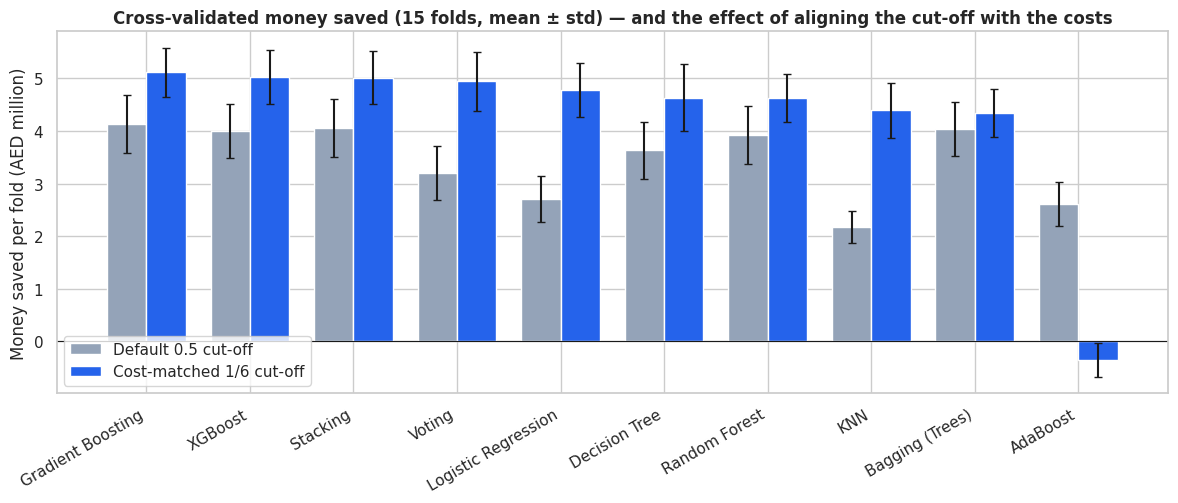

Gradient Boosting  default 0.5 cut-off        acc=89.60%  recall=33.51%  caught=63  good rejected=31  money saved=AED 4,768,240
Gradient Boosting  cost-matched 1/6 cut-off   acc=84.67%  recall=53.72%  caught=101  good rejected=143  money saved=AED 5,815,160


In [17]:
fig, ax = plt.subplots(figsize=(12, 5.2))
order = lb_cost.sort_values("CV_money_1_6", ascending=False).Model.tolist()
xx = np.arange(len(order)); wd = 0.38
ax.bar(xx - wd/2, [np.mean(cv[m]["0.5"]) / 1e6 for m in order], wd, yerr=[np.std(cv[m]["0.5"]) / 1e6 for m in order],
       color="#94a3b8", capsize=3, label="Default 0.5 cut-off")
ax.bar(xx + wd/2, [np.mean(cv[m]["1/6"]) / 1e6 for m in order], wd, yerr=[np.std(cv[m]["1/6"]) / 1e6 for m in order],
       color="#2563eb", capsize=3, label="Cost-matched 1/6 cut-off")
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(xx); ax.set_xticklabels(order, rotation=30, ha="right")
ax.set_ylabel("Money saved per fold (AED million)")
ax.set_title("Cross-validated money saved (15 folds, mean ± std) — and the effect of aligning the cut-off with the costs", fontweight="bold")
ax.legend(loc="lower left"); plt.tight_layout(); plt.savefig("cv_money_chart.png", dpi=160, bbox_inches="tight"); plt.show()

# Champion before vs after the cost-matched cut-off (test set)
pc = fitted[champion_name].predict_proba(X_test)[:, 1]
for lab, thr in [("default 0.5 cut-off", 0.5), ("cost-matched 1/6 cut-off", THRESH)]:
    yp_ = (pc >= thr).astype(int)
    print(f"{champion_name:<18} {lab:<26} acc={accuracy_score(y_test, yp_):.2%}  recall={recall_score(y_test, yp_):.2%}  "
          f"caught={int(((yp_==1)&(np.array(y_test)==1)).sum())}  good rejected={int(((yp_==1)&(np.array(y_test)==0)).sum())}  "
          f"money saved=AED {money_saved(y_test, yp_, loan_test):,.0f}")

### What the cost-matched cut-off does

- It helps almost every model, most of all the ones that were timid at 0.5. Cross-validated money saved rises from AED 2.71 M → 4.78 M (Logistic Regression), 3.19 M → 4.94 M (Voting), 2.17 M → 4.39 M (KNN) and 4.13 M → **5.12 M (Gradient Boosting)**. Of the models that work, Bagging gains least (4.04 M → 4.34 M): fully grown trees produce coarse, over-confident probabilities.
- **AdaBoost breaks:** at 1/6 it rejects everybody (accuracy 12.53 %, exactly the "reject everyone" result, AED −317,100). A fixed probability cut-off only works with probabilities that are spread out sensibly, and AdaBoost's are not.
- **Gradient Boosting on the test set:** AED 4,768,240 → **AED 5,815,160 (+AED 1,046,920, +22 %)**. It now catches 101 of 188 defaulters (recall 33.5 % → 53.7 %), saving AED 7.78 M of loans for AED 1.96 M of lost interest; 143 of the 1,312 good customers (10.9 %) are turned away.
- **The accuracy lesson again:** accuracy *falls* from 89.6 % to 84.7 % — below even "approve everyone" (87.5 %) — while money saved rises by over a million dirhams.

## Step 5 — The Verdict (to QuickLoan leadership)

**Recommendation: deploy Gradient Boosting, run with a cost-matched decision rule — reject when the predicted default probability is ≥ 1/6 (= interest ÷ (1 + interest)).**

| Test set: 1,500 loans, AED 75.2 M requested, 188 defaulters (AED 12.27 M principal) | Accuracy | Defaulters caught | Good customers rejected | **Money saved vs approving everyone** |
|---|---|---|---|---|
| Approve everyone | 87.5 % | 0 / 188 | 0 | AED 0 |
| Gradient Boosting, default 0.5 rule (bake-off champion) | 89.6 % | 63 / 188 (33.5 %) | 31 | **AED 4,768,240** |
| **Gradient Boosting, cost-matched 1/6 rule (recommended)** | 84.7 % | 101 / 188 (53.7 %) | 143 (10.9 %) | **AED 5,815,160** (≈ AED 3,900 per applicant) |

**Why this model — in money terms.** It topped the leaderboard and also had the best average in 15-fold cross-validation under both decision rules. It saves AED 0.99 M more than the best single model (Decision Tree) and about AED 1.0 M more once the cut-off is matched to the costs. XGBoost is statistically indistinguishable and is a perfectly good alternative; Stacking is no better yet slower and more complex; Logistic Regression's strong-looking single-split score at the 1/6 rule did not survive cross-validation.

**Trade-offs we accept.**
- **Accuracy:** we give up about 5 points (89.6 % → 84.7 %) and end up below "approve everyone" on accuracy — because accuracy ignores that a missed defaulter costs five times as much as a lost customer.
- **Recall vs customer friction:** we catch 38 more defaulters than the default rule but turn away 112 more good customers; at a 20 % interest assumption that trade is clearly profitable (the net saving would only disappear at an interest rate far above any realistic level).
- **Interpretability:** boosted trees are harder to explain than a logistic regression or a single tree. Mitigation: every decision carries a default probability, and `debt_to_income` and `past_defaults` drive about 68 % of the model's importance. If explainability is mandatory, a Decision Tree with the same 1/6 rule is the transparent fallback (cross-validated AED 4.63 M, ~10 % below Gradient Boosting).

**Caveats.** One dataset of 6,000 loans, a single 188-defaulter test set (per-fold noise ≈ AED 0.5 M), no hyper-parameter tuning, and a fixed 20 % interest assumption. Even the recommended model still lets 87 defaulters (AED 4.49 M of principal) through; the cut-off must be recomputed if the interest or loss assumptions change, and the model should be monitored after deployment.

## Stretch — save the model & power the dashboard

Two files are saved in the format `app.py` expects (`{'model': ..., 'columns': ...}`):
- **`loan_model.joblib`** — the bake-off champion exactly as scored on the leaderboard (default 0.5 rule).
- **`loan_model_costaware.joblib`** — the same champion with the cost-matched 1/6 cut-off (the recommended production setting).

Because `app.py` uses the very same split (`test_size=0.25, random_state=1, stratify=y`), its *Money card* must reproduce the notebook's numbers — verified below.

In [18]:
champion_model = fitted[champion_name]

# (1) Bake-off champion, default decision rule -> exactly what the leaderboard scored
joblib.dump({"model": champion_model, "columns": list(X_train.columns)}, "loan_model.joblib")

# (2) Same champion with the cost-matched 1/6 cut-off (recommended production setting).
#     FixedThresholdClassifier is a standard scikit-learn wrapper, so app.py needs no changes.
prod_model = FixedThresholdClassifier(FrozenEstimator(champion_model), threshold=THRESH,
                                      response_method="predict_proba").fit(X_train, y_train)
joblib.dump({"model": prod_model, "columns": list(X_train.columns)}, "loan_model_costaware.joblib")

# Re-create the dashboard's "money card" logic (copied from app.py) on both saved files
def encode(d, cols): return pd.get_dummies(d, columns=["home_ownership"]).reindex(columns=cols, fill_value=0)
for fname in ["loan_model.joblib", "loan_model_costaware.joblib"]:
    M = joblib.load(fname); mdl, cols = M["model"], M["columns"]
    Xd = encode(df.drop(columns="default"), cols); yd = df["default"]
    Xtr_, Xte_, ytr_, yte_, lo_tr, lo_te = train_test_split(Xd, yd, df["loan_amount"], test_size=0.25, random_state=1, stratify=yd)
    pr = mdl.predict(Xte_)
    caught = int(((pr == 1) & (yte_.values == 1)).sum()); wrong = int(((pr == 1) & (yte_.values == 0)).sum())
    print(f"{fname:<30} money saved AED {money_saved(yte_, pr, lo_te):>12,.0f} | defaulters caught {caught}/{int(yte_.sum())} | good rejected {wrong}")

# sanity: the first file must reproduce the leaderboard figure
assert abs(money_saved(yte_, joblib.load('loan_model.joblib')['model'].predict(Xte_), lo_te) - champ.Money_saved) < 1e-6
print("\nloan_model.joblib reproduces the leaderboard value exactly.")

# Decision-card example: the dashboard's default applicant
applicant = dict(age=35, annual_income=90000, loan_amount=40000, loan_term_months=36, employment_years=4.0,
                 credit_history_months=60, num_existing_loans=1, past_defaults=0,
                 debt_to_income=round(40000/90001, 2), home_ownership="rent")
Xa = encode(pd.DataFrame([applicant]), list(X_train.columns))
for fname in ["loan_model.joblib", "loan_model_costaware.joblib"]:
    mdl = joblib.load(fname)["model"]
    print(f"{fname:<30} -> {'REJECT' if mdl.predict(Xa)[0] == 1 else 'APPROVE'}  (P(default) = {mdl.predict_proba(Xa)[0][1]:.1%})")

loan_model.joblib              money saved AED    4,768,240 | defaulters caught 63/188 | good rejected 31
loan_model_costaware.joblib    money saved AED    5,815,160 | defaulters caught 101/188 | good rejected 143

loan_model.joblib reproduces the leaderboard value exactly.
loan_model.joblib              -> APPROVE  (P(default) = 5.6%)
loan_model_costaware.joblib    -> APPROVE  (P(default) = 5.6%)


---
**To run the dashboard:** keep `app.py`, `loans.csv` and `loan_model.joblib` in one folder and run `streamlit run app.py`.  
To demo the recommended production setting, run it with `loan_model_costaware.joblib` renamed to `loan_model.joblib`.